In [17]:
!ls /ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/model_512_no_dispersion/
!cat /ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/model_512_no_dispersion/410.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc2048_metadata.yaml

410.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc2048
410.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc2048_metadata.yaml
train.features.npy
datastore: IVFPQ
corse_index: FlatL2
nclusters: 2048
nprobe: 32
code_size: 64
ntotal: 21507934
dim: 512



In [41]:
!ls /ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/model_512_dispersion
!cat /ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/model_512_dispersion/582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc2048_meta.yaml

582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_512_4096
582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc2048
582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc2048_meta.yaml
582.train.features.npy
582.train.targets.npy
datastore: IVFPQ
corse_index: FlatL2
nclusters: 2048
nprobe: 32
code_size: 64
ntotal: 21507934
dim: 512
features_model: /ivi/ilps/personal/etokarc/models/translation/00582_ro_en_transformer_dispersion_ft/checkpoint_best.pt


In [ ]:
from collections import defaultdict
from pathlib import Path
import faiss
import numpy as np
from argparse import Namespace
from tqdm.auto import tqdm

import torch

def load_yaml(yaml_path):
    import yaml
    with open(yaml_path, 'r') as f:
        return yaml.safe_load(f)

class Embedding:
    def __init__(self, base_path, features_path, yaml_path, faiss_path, normalize=False):
        self.features_path = Path(base_path) / features_path
        self.faiss_path = Path(base_path) / faiss_path
        self.args = Namespace(**load_yaml(Path(base_path) / yaml_path))
        print(self.args)
        self.keys = None
        self.knn_index = None
        # self.vals = None

        self.normalize = normalize
    
    def load_raw(self):
        # /ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/model_512_no_dispersion/train.features.npy
        # large file containing the raw embeddings, need to be loaded into memory with memory mapping
        self.keys = np.memmap(self.features_path, dtype=np.float32, mode='r', shape=(self.args.ntotal, self.args.dim))
        # self.vals = np.memmap(self.args.values_path, dtype=np.int32, mode='r', shape=(self.args.ntotal,)) 

    def load_faiss(self):
        # res = faiss.StandardGpuResources()
        # co = faiss.GpuClonerOptions()
        # co.useFloat16 = True
        # knn_index_file = 
        self.knn_index: faiss.Index = faiss.read_index(str(self.faiss_path))
        # self.knn_index = faiss.index_cpu_to_gpu(res,0,self.knn_index,co)
        self.knn_index.nprobe = self.args.nprobe
        self.knn_k = self.args.nclusters
        # self.knn_lambda = self.args.knn_lambda  # knn mt
        # self.knn_temperature = 
        self.knn_metric = "L2"
        # print("load vals to retrieve vocab indices")
        # vals_memmap = np.memmap(f"{self.knn_index_file}_vals.npy", dtype=np.int32, mode='r', shape=(self.knn_index.ntotal,))
        # self.vals = torch.zeros(self.knn_index.ntotal, dtype=torch.int64)
        # self.vals[:] = torch.from_numpy(vals_memmap[:])

    def retrieve(self, q, k=1):
        # Returns distances and indices of the k nearest neighbors for each query vector q
        if q.ndim == 1:
            q = np.expand_dims(q, axis=0)
        # q to fp16
        q = q.astype(np.float16)
        # q: query vector
        # k: number of nearest neighbors to retrieve
        if self.knn_index is None:
            self.load_faiss()
        D, I = self.knn_index.search(q, k)  # distances and indices of the nearest neighbors
        return D, I
    
    def average_k_neares_neighbour_distance(self, n=1000, k=10, use_faiss_distances=False):
        # Returns the average distance of the k nearest neighbors for each vector in the dataset
        if self.knn_index is None:
            self.load_faiss()
        n_embeddings = self.knn_index.ntotal
        n_qs = np.random.choice(n_embeddings, n, replace=False)
        Ds = defaultdict(list) # nearest-neighbour distances
        for q in tqdm(n_qs):
            D, I = self.retrieve(self.keys[q], k)
            # D: distances of the k nearest neighbors
            if use_faiss_distances:
                for i in range(k):
                    Ds[i].append(D[0][i])
            else:
                # calculate distances using the original vectors
                for i in range(k):
                    Ds[i].append(np.linalg.norm(self.keys[q] - self.keys[I[0][i]]))
        return Ds

    
    def emb(self, idx):
        if self.keys is None:
            self.load_raw()
        if self.normalize:
            return self.keys[idx] / np.linalg.norm(self.keys[idx])
        else:
            return self.keys[idx]

/home/stroshi/miniconda3/envs/evgeniia/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
embedding_baseline = Embedding(
        base_path='/ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/model_512_no_dispersion/',
        features_path='train.features.npy',
        yaml_path="410.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc4096_metadata.yaml",
        faiss_path='410.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc4096'
    )
embedding_dispersion = Embedding(
        base_path='/ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/model_512_dispersion/',
        features_path='582.train.features.npy',
        yaml_path="582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc2048_meta.yaml",
        faiss_path='582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_512_4096'
    )
embedding_baseline.load_raw()
embedding_dispersion.load_raw()

Namespace(code_size=64, corse_index='FlatL2', datastore='IVFPQ', dim=512, nclusters=4096, nprobe=32, ntotal=21507934)
Namespace(code_size=64, corse_index='FlatL2', datastore='IVFPQ', dim=512, features_model='/ivi/ilps/personal/etokarc/models/translation/00582_ro_en_transformer_dispersion_ft/checkpoint_best.pt', nclusters=2048, nprobe=32, ntotal=21507934)


# k‑nearest‑neighbour (k‑NN) radius statistics

In [4]:
embedding_baseline.load_faiss()
embedding_dispersion.load_faiss()


In [5]:
print(embedding_dispersion.knn_index.nlist)
print(embedding_baseline.knn_index.nlist)

4096
4096


In [ ]:
embedding_dispersion.knn_index.


<faiss.swigfaiss.IndexIVFPQ; proxy of <Swig Object of type 'faiss::IndexIVFPQ *' at 0x7f55d0d7d030> >

In [46]:
Ds_baseline = embedding_baseline.average_k_neares_neighbour_distance(n=100, k=10)
Ds_dispersion = embedding_dispersion.average_k_neares_neighbour_distance(n=100, k=10)
# Ds[i] are the distances of a random vector to its i-th nearest neighbor

100%|██████████| 100/100 [00:26<00:00,  3.84it/s]


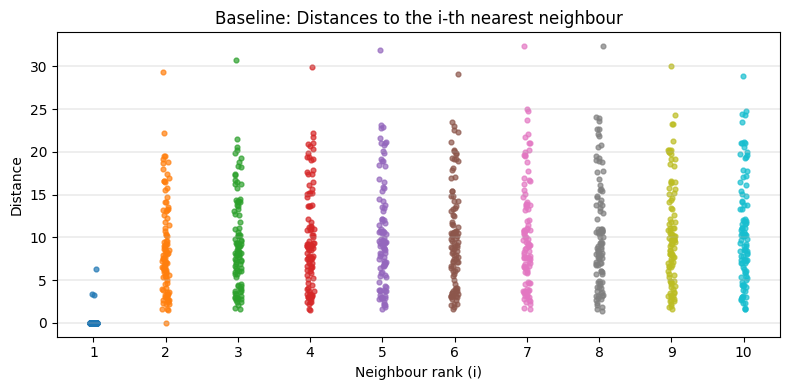

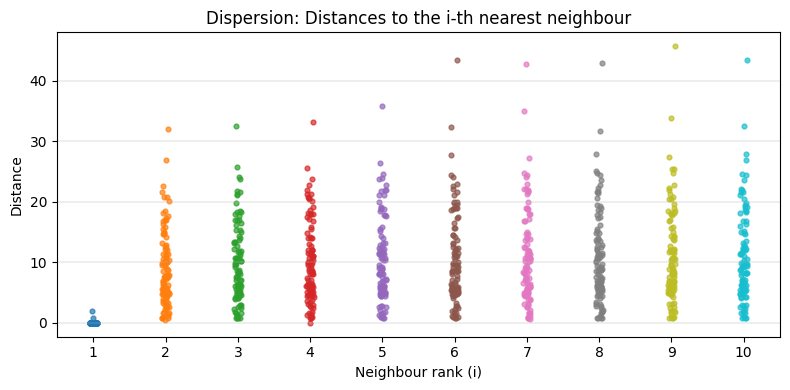

In [49]:
import numpy as np
import matplotlib.pyplot as plt

def visualize_average_k_neares_neighbour_distance(Ds, title):
    plt.figure(figsize=(8, 4))
    for i in range(len(Ds)):
        # add ±0.05 jitter along x so points form a “cloud” in each column
        x_jitter = (np.random.rand(len(Ds[i])) - 0.5) * 0.1
        plt.scatter(np.full(len(Ds[i]), i) + x_jitter,
                    Ds[i],
                    s=12,
                    alpha=0.7)
    plt.xticks(range(len(Ds)), [f"{i+1}" for i in range(len(Ds))])
    plt.xlabel("Neighbour rank (i)")
    plt.ylabel("Distance")
    plt.title(title)
    plt.grid(True, axis="y", linewidth=0.3)
    plt.tight_layout()
    plt.show()


visualize_average_k_neares_neighbour_distance(Ds_baseline, "Baseline: Distances to the i-th nearest neighbour")
visualize_average_k_neares_neighbour_distance(Ds_dispersion, "Dispersion: Distances to the i-th nearest neighbour")

In [15]:
!ls /ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/model_512_dispersion

582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc2048
582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc2048_meta.yaml
582.train.features.npy
582.train.targets.npy


In [ ]:
q = embedding.emb(0)
D, I = embedding.retrieve(q, k=100)
print("Distances: ", D)
print("Indices: ", I)

Distances:  [[ 81.861725  81.861725  81.861725  81.861725  81.861725  81.861725
   81.861725  81.861725  81.861725  81.861725  81.861725  81.861725
   81.861725  81.861725  81.861725  81.861725  81.861725  81.861725
   81.861725  81.861725  81.861725  81.861725  81.861725  81.861725
   81.861725  81.861725  81.861725  81.861725  81.861725  81.861725
   81.861725  81.861725  81.861725  81.861725  81.861725  81.861725
   81.861725  81.861725  81.861725  81.861725  81.861725  81.861725
   81.861725  81.861725  81.861725  81.861725  81.861725  81.861725
   81.861725  81.861725  81.861725  81.861725  81.861725  81.861725
   81.861725  81.861725  81.861725  81.861725  81.861725  81.861725
   81.861725  81.861725  81.861725  81.861725  81.861725  81.861725
   81.861725  81.861725  81.861725  81.861725  81.861725  81.861725
   81.861725  81.861725  81.861725  81.861725  81.861725  81.861725
  180.7788   187.36633  188.71188  192.09221  193.59566  194.24306
  194.84325  195.51428  196.37015  19

In [100]:
def dist(a, b, p="L2"):
    return np.linalg.norm(a - b) if p == "L2" else np.dot(a, b)
for j in range(100):
    d = dist(embedding.emb(0), embedding.emb(j))
    print(f"Distance between 0 and {j}: {d}")
    # print("Norm of emb(0)", np.linalg.norm(embedding.emb(0)))
    # print("Norm of emb(j)", np.linalg.norm(embedding.emb(j)))

# print distances and indices to top 100 nearest neighbors
distances = []
for i in range(10000):
    q = embedding.emb(i)
    distances.append(dist(q, embedding.emb(0)))

# get top 100:
top_100 = np.argsort(distances)[:100]
print("Top 100 nearest neighbors to 0: ", top_100)


Distance between 0 and 0: 0.0
Distance between 0 and 1: 0.0
Distance between 0 and 2: 0.0
Distance between 0 and 3: 0.0
Distance between 0 and 4: 0.0
Distance between 0 and 5: 0.0
Distance between 0 and 6: 0.0
Distance between 0 and 7: 0.0
Distance between 0 and 8: 0.0
Distance between 0 and 9: 0.0
Distance between 0 and 10: 0.0
Distance between 0 and 11: 0.0
Distance between 0 and 12: 0.0
Distance between 0 and 13: 0.0
Distance between 0 and 14: 0.0
Distance between 0 and 15: 0.0
Distance between 0 and 16: 0.0
Distance between 0 and 17: 0.0
Distance between 0 and 18: 0.0
Distance between 0 and 19: 0.0
Distance between 0 and 20: 0.0
Distance between 0 and 21: 0.0
Distance between 0 and 22: 0.0
Distance between 0 and 23: 0.0
Distance between 0 and 24: 0.0
Distance between 0 and 25: 0.0
Distance between 0 and 26: 0.0
Distance between 0 and 27: 0.0
Distance between 0 and 28: 0.0
Distance between 0 and 29: 0.0
Distance between 0 and 30: 0.0
Distance between 0 and 31: 0.0
Distance between 0

## UMAP

In [ ]:
# import numpy as np

# embeddings = embedding_baseline
# title = "Baseline"

# N = embeddings.keys.shape[0]           # total vectors
# m = 10_000                        # how many you want to plot
# rng = np.random.default_rng(42)   # reproducible sampling
# sub_ix = rng.choice(N, m, replace=False)

# sample = embeddings.keys[sub_ix].astype(np.float32)   # cast once → compact
# sample


In [7]:
import faiss, numpy as np
D, I = kmeans.index.search(train_vecs, 1)   # squared distances & labels
centroids = kmeans.centroids.reshape(k, -1)

# cluster sizes
sizes = np.bincount(I.ravel(), minlength=k)

# intra‑cluster dispersion: mean sqrt distance per cluster
intra = np.zeros(k)
for c in range(k):
    mask = (I == c).ravel()
    if mask.any():
        intra[c] = np.sqrt(D[mask].mean())

# inter‑cluster separation: full centroid × centroid matrix
from scipy.spatial.distance import pdist, squareform
inter = squareform(pdist(centroids, metric='euclidean'))
min_inter = inter[np.triu_indices(k, 1)].min()   # smallest centroid gap


NameError: name 'kmeans' is not defined